# PROYECTO DE ANALÍTICA DE DATOS - MACI 2026
**Alumno:** Keyden Urbina P.

**Dataset:** Amazon Products Sales Dataset 2025

**Fuente:** https://www.kaggle.com/datasets/ikramshah512/amazon-products-sales-dataset-42k-items-2025?resource=download

## Etapa 1: Explorar el dataset a utilizar

**Objetivo:** Revisar el dataset para conocer la naturaleza, tipo y calidad de los datos, evaluando completitud, existencia de datos nulos, inconsistentes, incongruentes, y entender bajo una mirada global el dataset que se va a utilizar.

**Conclusión de la revisión:** 

Se revisó el dataset y se pudo observar que:

1. Se compone de 42.672 filas y 16 columnas.

2. Todos los datos son tipo 'str' (cadena). Columnas como 'rating' se esperaría que fuesen datos numéricos.

3. Aparentemente, se pobló el dataset mediante scrapping por lo que incrementa el riesgo de error por la extracción.

### Paso 1 -- Se importan las librerías necesarias para el análisis exploratorio de datos

In [1]:
%matplotlib inline

try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    from pathlib import Path
    from IPython.display import display
    print("¡Librerías importadas y validadas con éxito!")
    print(f"- Pandas versión: {pd.__version__}")
    print(f"- NumPy versión: {np.__version__}")
    print(f"- Seaborn versión: {sns.__version__}")
except ImportError as e:
    print(f"Error al importar alguna librería: {e}")

# Rutas del proyecto (funciona desde notebooks/ o desde la raíz)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = BASE / "data" / "raw"
PROCESADO = BASE / "data" / "procesado"
FIGURAS = BASE / "figuras"
PROCESADO.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
print(f"\nRaíz del proyecto: {BASE}")

¡Librerías importadas y validadas con éxito!
- Pandas versión: 3.1.0
- NumPy versión: 2.5.4
- Seaborn versión: 0.13.2

Raíz del proyecto: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos


### Paso 2 -- Se descargan los datos del archivo CSV

In [2]:
df = pd.read_csv(RAW / "amazon_products_sales_data_uncleaned.csv")
print(f"Dataset cargado: {df.shape[0]:,} filas | {df.shape[1]} columnas")
df.head()

Dataset cargado: 42,675 filas | 16 columnas


,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314.00,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6 out of 5 stars,"35,882",10K+ bought in past month,NaN,basic variant price: $162.24,No Discount,Best Seller,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61SUj2aKoE...,/Apple-Cancellation-Transparency-Personalized-...,2025-08-21 11:14:29
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8 out of 5 stars,"28,988",10K+ bought in past month,NaN,basic variant price: $72.74,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61bMNCeAUA...,/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref...,2025-08-21 11:14:29


### Paso 3 -- Se revisa el tamaño del dataset, la estructura de los datos

In [3]:
# 1. Tamaño del dataset
filas, columnas = df.shape
print(f"Filas: {filas:,} | Columnas: {columnas}")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Completitud global: % de celdas con dato sobre el total de celdas
completitud = df.notnull().sum().sum() / df.size * 100
print(f"Completitud global: {completitud:.2f}%\n")

# 2. Estructura: tipo de dato, no nulos y % no nulos por columna
estructura = pd.DataFrame({
    "tipo": df.dtypes,
    "no_nulos": df.notnull().sum(),
    "% no_nulos": (df.notnull().mean() * 100).round(2)
}).sort_values("% no_nulos")

display(estructura)

Filas: 42,675 | Columnas: 16
Memoria: 67.24 MB
Completitud global: 87.59%



,tipo,no_nulos,% no_nulos
sustainability_badges,str,3408,7.99
buy_box_availability,str,28022,65.66
current/discounted_price,str,30926,72.47
delivery_details,str,30955,72.54
bought_in_last_month,str,39458,92.46
product_url,str,40606,95.15
rating,str,41651,97.60
number_of_reviews,str,41651,97.60
title,str,42675,100.00
price_on_variant,str,42675,100.00


## Etapa 2: Diagnóstico de calidad de datos

**Objetivo:** Revisar el dataset para conocer en profundidad la calidad de los datos, evaluando si es viable su uso para realizar el modelo e identificar la necesidad de limpieza, transformación o eliminación de la data que se requiera.

**Conclusión de la revisión:** 

Se revisó el dataset y se pudo observar que:

1. En el dataset se acumulan un total de 150.744 datos nulos distribuidos a lo largo de distintas columnas. Ejemplos: sustainability_badges (39,267 nulos - 92,01%), bought_in_last_month (32,177 nulos - 75,40%), product_url (20,694 nulos - 48,50%). Por ello, las insignias de sustentabilidad y las compras mensuales presentan una ausencia crítica de información, mientras que los precios y las reseñas se mantienen como las variables más completas del estudio.

2. Se observa que existe completitud de un 87,6% en todo el dataset.

3. El dataset contiene 42.675 registros, sin duplicados exactos. Sin embargo, solo el 5,1% de las filas (2.175) está completo, por lo que eliminar todos los registros con valores faltantes implicaría perder el 94,9% de la información; esta alternativa se descarta.

4. La distribución de nulos por fila no es aleatoria. El 49,7% de los registros presenta un único valor faltante, concentrado en la columna [sustainability_badges], que registra un 99,3% de nulos. Se propone eliminar esta variable en lugar de las filas afectadas, lo que permite recuperar como completos a la mayoría de esos registros.

5. El 23,1% de los registros (9.846) carece de las mismas cuatro variables [current/discounted_price], [buy_box_availability], [delivery_details], [ustainability_badges] lo que sugiere un segmento de productos con características distintas (por ejemplo, sin oferta activa) más que un error de captura. Este grupo se tratará de forma diferenciada.

6. Finalmente, los 942 registros con cinco o más valores faltantes (2,2%) se eliminarán, al no contener información suficiente para ser imputados.

7. Tipos de datos inconsistentes en formato. Las 16 columnas se almacenan como 'str', por lo que no existe una estructura numérica o temporal tipada que permita analizar fácilmente la data.

8. Los datos numéricos vienen con formato de texto. El rating se registra como “4.6 out of 5 stars”, los precios con signos y separadores de miles, y las reseñas mezclan dos formatos. Sin conversión, no es posible calcular promedios, correlaciones ni entrenar modelos.

9. Existen nulos que no se ven. El 49,3% de price_on_variant contiene el texto “nan”, que pandas cuenta como dato válido. Un análisis sin revisión habría reportado 0% de nulos en esa variable.

10. En cinco variables el vacío indica ausencia del atributo: 71,2% de productos sin descuento, 95,6% sin distintivo, 95,4% sin cupón, 34,3% sin botón de compra y 92% sin sello sustentable. Estos valores se codificarán como “no tiene”, no se imputarán, ya que hacerlo crearía información falsa.

11. Hay un segmento de productos no disponibles. El 27,5% de los registros carece a la vez de precio actual y de fecha de entrega. El patrón coincidente apunta a productos sin opción de compra y no a fallas aleatorias de captura.

12. El mismo producto aparece varias veces. No hay filas idénticas, pero 42.675 registros corresponden a 8.808 títulos. Tratar cada fila como un producto distinto sobrestimaría el catálogo casi cinco veces. Tampoco hay un atributo key que permita identificar al producto. Se esperaría obtenerlo con la URL. La ausencia de un identificador explícito de producto y de una categoría comercial requiere evaluar la unicidad de los registros y la disponibilidad de variables explicativas.

13. Se detectaron formatos mezclados en cinco variables, residuos de HTML, cupones que combinan montos en $ y en %, y nombres de variables que no reflejan su contenido (is_best_seller tiene 12 categorías, no un sí/no). Esto pudo ser producto del scrapping.

Finalmente, tras la revisión el riesgo por inconsistencias en formatos, naturaleza de los datos, atributos poco explicativos y problemas de integridad es crítico. Todo esto justifica la necesidad de implementar una etapa de depuración, estandarización y validación de datos antes de aplicar algoritmos de clasificación.

### Paso 4 -- Revisión de datos nulos

In [4]:
# Nulos reales
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "% nulos": (df.isnull().mean() * 100).round(2)
})

# Columnas de texto: todo lo que no sea número, fecha ni booleano (compatible con pandas 2 y 3)
cols_texto = df.select_dtypes(exclude=["number", "datetime", "bool"]).columns

# Nulos ocultos tipo 1: la celda completa es un marcador de vacío ("nan", "-", "n/a"...)
falsos_nulos = ["", " ", "na", "n/a", "nan", "null", "none", "-", "--", "?", "sin dato"]

# Nulos ocultos tipo 2: el marcador está dentro del texto ("basic variant price: nan")
PATRON_NULO_TEXTO = r"\b(?:nan|null|none|n/a)\b"

nulos["ocultos_exactos"] = 0
nulos["ocultos_en_texto"] = 0
for col in cols_texto:
    s = df[col].dropna().astype(str).str.strip()
    es_exacto = s.str.lower().isin(falsos_nulos)
    en_texto = s.str.contains(PATRON_NULO_TEXTO, case=False, regex=True) & ~es_exacto
    nulos.loc[col, "ocultos_exactos"] = es_exacto.sum()
    nulos.loc[col, "ocultos_en_texto"] = en_texto.sum()

nulos["nulos_ocultos"] = nulos["ocultos_exactos"] + nulos["ocultos_en_texto"]
nulos["% ocultos"] = (nulos["nulos_ocultos"] / len(df) * 100).round(2)
nulos["% total"] = nulos["% nulos"] + nulos["% ocultos"]

# Duplicados exactos
dup_total = df.duplicated().sum()

display(nulos.sort_values("% total", ascending=False))
print(f"Filas duplicadas exactas: {dup_total:,} ({dup_total / len(df) * 100:.2f}%)")

# Ejemplos de nulos ocultos encontrados, para verificar que son vacíos reales
print("\nEjemplos de nulos ocultos por columna:")
for col in nulos.index[nulos["nulos_ocultos"] > 0]:
    s = df[col].dropna().astype(str).str.strip()
    marca = s.str.lower().isin(falsos_nulos) | s.str.contains(PATRON_NULO_TEXTO, case=False, regex=True)
    print(f"- {col}: {s[marca].value_counts().head(3).to_dict()}")

,nulos,% nulos,ocultos_exactos,ocultos_en_texto,nulos_ocultos,% ocultos,% total
sustainability_badges,39267,92.01,0,0,0,0.00,92.01
price_on_variant,0,0.00,0,21031,21031,49.28,49.28
buy_box_availability,14653,34.34,0,0,0,0.00,34.34
current/discounted_price,11749,27.53,0,0,0,0.00,27.53
delivery_details,11720,27.46,0,0,0,0.00,27.46
bought_in_last_month,3217,7.54,0,0,0,0.00,7.54
product_url,2069,4.85,0,0,0,0.00,4.85
rating,1024,2.40,0,0,0,0.00,2.40
number_of_reviews,1024,2.40,0,0,0,0.00,2.40
title,0,0.00,0,0,0,0.00,0.00


Filas duplicadas exactas: 0 (0.00%)

Ejemplos de nulos ocultos por columna:
- price_on_variant: {'basic variant price: nan': 21031}


In [5]:
nulos_por_fila = df.isnull().sum(axis=1)

# Para cada fila, la lista de columnas que tiene vacías
cols_vacias = df.isnull().apply(lambda fila: ", ".join(fila[fila].index), axis=1)

for n in [1, 4]:
    grupo = cols_vacias[nulos_por_fila == n]
    print(f"\n=== Filas con {n} nulo(s): {len(grupo):,} ===")

    # Combinaciones de columnas vacías más frecuentes en este grupo
    combinaciones = grupo.value_counts().head(5)
    resumen = pd.DataFrame({
        "filas": combinaciones,
        "% del grupo": (combinaciones / len(grupo) * 100).round(1)
    })
    display(resumen)

# % de nulos de cada columna en el dataset completo (para el [X]%)
print("\n=== % de nulos por columna (dataset completo) ===")
display((df.isnull().mean() * 100).round(1).sort_values(ascending=False).to_frame("% nulos"))


=== Filas con 1 nulo(s): 21,203 ===


,filas,% del grupo
sustainability_badges,21059,99.3
bought_in_last_month,86,0.4
buy_box_availability,30,0.1
product_url,17,0.1
current/discounted_price,10,0.0



=== Filas con 4 nulo(s): 9,846 ===


,filas,% del grupo
"current/discounted_price, buy_box_availability, delivery_details, sustainability_badges",9616,97.7
"rating, number_of_reviews, bought_in_last_month, sustainability_badges",227,2.3
"bought_in_last_month, buy_box_availability, delivery_details, sustainability_badges",1,0.0
"rating, number_of_reviews, buy_box_availability, sustainability_badges",1,0.0
"rating, number_of_reviews, sustainability_badges, product_url",1,0.0



=== % de nulos por columna (dataset completo) ===


,% nulos
sustainability_badges,92.0
buy_box_availability,34.3
current/discounted_price,27.5
delivery_details,27.5
bought_in_last_month,7.5
product_url,4.8
rating,2.4
number_of_reviews,2.4
title,0.0
price_on_variant,0.0


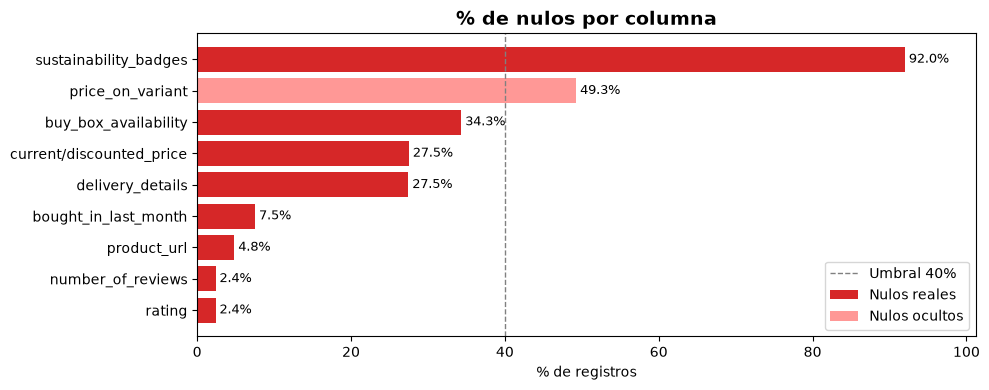


Gráficos guardados en: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos/figuras


In [6]:
# =========================================================
# GRÁFICO 1: % DE NULOS POR COLUMNA
# =========================================================
g1 = nulos[nulos["% total"] > 0].sort_values("% total")

fig, ax = plt.subplots(figsize=(10, max(4, len(g1) * 0.4)))
if g1.empty:
    ax.text(0.5, 0.5, "Sin nulos en ninguna columna", ha="center", va="center", fontsize=14)
    ax.axis("off")
else:
    ax.barh(g1.index, g1["% nulos"], color="#d62728", label="Nulos reales")
    ax.barh(g1.index, g1["% ocultos"], left=g1["% nulos"], color="#ff9896", label="Nulos ocultos")
    for i, v in enumerate(g1["% total"]):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.axvline(40, color="gray", linestyle="--", linewidth=1, label="Umbral 40%")
    ax.set_xlabel("% de registros")
    ax.set_xlim(0, max(100, g1["% total"].max() * 1.1))
    ax.legend(loc="lower right")
ax.set_title("% de nulos por columna", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURAS / "01_nulos_por_columna.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

print(f"\nGráficos guardados en: {FIGURAS}")


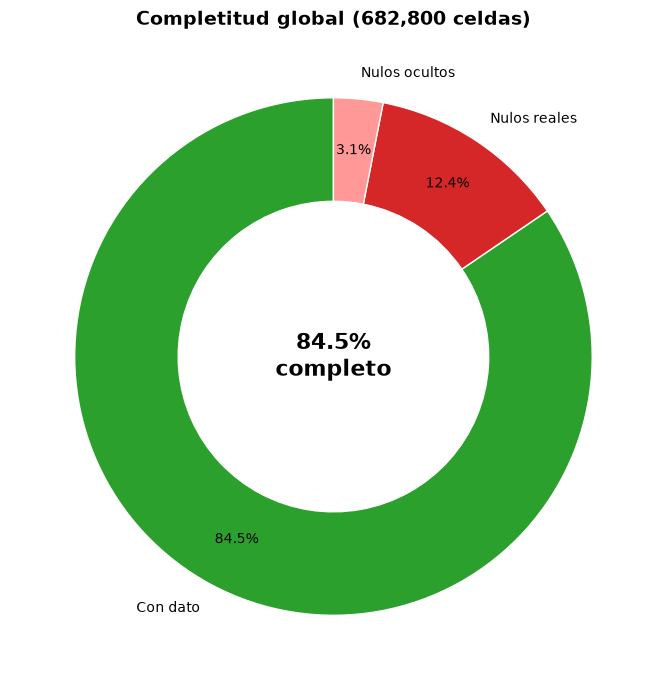


Gráficos guardados en: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos/figuras


In [7]:
# =========================================================
# GRÁFICO 2: COMPLETITUD GLOBAL
# =========================================================
celdas_nulas = df.isnull().sum().sum()
celdas_ocultas = nulos["nulos_ocultos"].sum()
celdas_ok = df.size - celdas_nulas - celdas_ocultas

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie([celdas_ok, celdas_nulas, celdas_ocultas],
       labels=["Con dato", "Nulos reales", "Nulos ocultos"],
       colors=["#2ca02c", "#d62728", "#ff9896"],
       autopct=lambda p: f"{p:.1f}%" if p > 0 else "",
       startangle=90, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, f"{celdas_ok / df.size * 100:.1f}%\ncompleto",
        ha="center", va="center", fontsize=16, fontweight="bold")
ax.set_title(f"Completitud global ({df.size:,} celdas)", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURAS / "02_completitud_global.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

print(f"\nGráficos guardados en: {FIGURAS}")

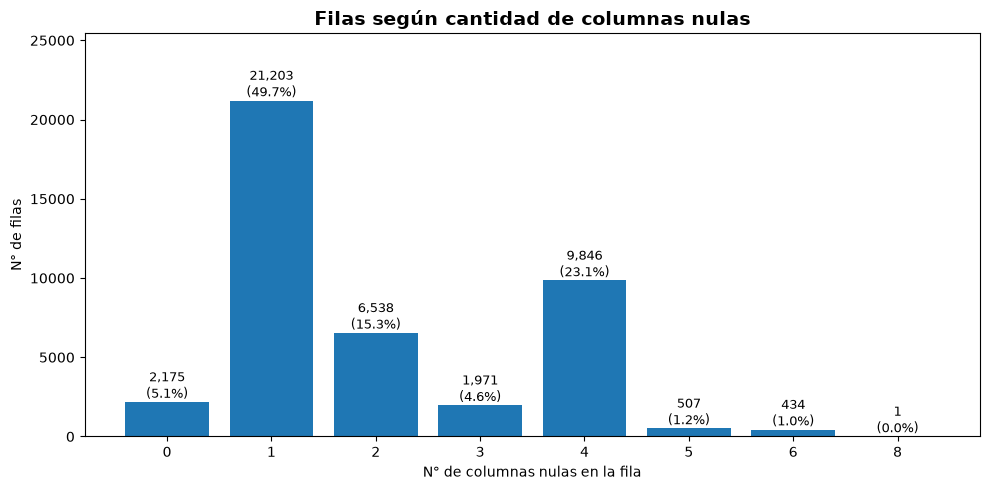


Gráficos guardados en: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos/figuras


In [8]:
# =========================================================
# GRÁFICO 3: FILAS SEGÚN CANTIDAD DE COLUMNAS NULAS
# =========================================================
nulos_fila = df.isnull().sum(axis=1).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(nulos_fila.index.astype(str), nulos_fila.values, color="#1f77b4")
for b, v in zip(barras, nulos_fila.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_title("Filas según cantidad de columnas nulas", fontsize=14, fontweight="bold")
ax.set_xlabel("N° de columnas nulas en la fila")
ax.set_ylabel("N° de filas")
ax.set_ylim(0, nulos_fila.max() * 1.2)
plt.tight_layout()
fig.savefig(FIGURAS / "03_nulos_por_fila.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

print(f"\nGráficos guardados en: {FIGURAS}")

In [9]:
# Determinación de las columnas con nulos más frecuentes en filas con 1 y 4 nulos
nulos_por_fila = df.isnull().sum(axis=1)

for n in [1, 4]:
    grupo = df[nulos_por_fila == n]
    print(f"\n=== Filas con {n} nulo(s): {len(grupo):,} ===")
    print("Columnas vacías más frecuentes en este grupo:")
    print(grupo.isnull().sum().loc[lambda s: s > 0].sort_values(ascending=False).to_string())


=== Filas con 1 nulo(s): 21,203 ===
Columnas vacías más frecuentes en este grupo:
sustainability_badges       21059
bought_in_last_month           86
buy_box_availability           30
product_url                    17
current/discounted_price       10
delivery_details                1

=== Filas con 4 nulo(s): 9,846 ===
Columnas vacías más frecuentes en este grupo:
sustainability_badges       9846
buy_box_availability        9618
delivery_details            9617
current/discounted_price    9616
rating                       229
number_of_reviews            229
bought_in_last_month         228
product_url                    1


### Paso 5 -- Revisión de duplicados

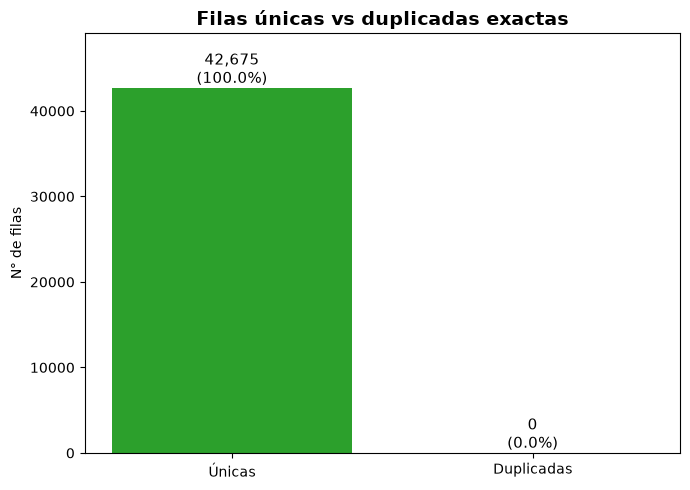


Gráficos guardados en: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos/figuras


In [10]:
# =========================================================
# GRÁFICO 4: FILAS ÚNICAS VS DUPLICADAS
# =========================================================
unicas = len(df) - dup_total

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["Únicas", "Duplicadas"], [unicas, dup_total], color=["#2ca02c", "#d62728"])
for b, v in zip(barras, [unicas, dup_total]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=11)
ax.set_title("Filas únicas vs duplicadas exactas", fontsize=14, fontweight="bold")
ax.set_ylabel("N° de filas")
ax.set_ylim(0, len(df) * 1.15)
plt.tight_layout()
fig.savefig(FIGURAS / "04_duplicados.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

print(f"\nGráficos guardados en: {FIGURAS}")

### Paso 6 -- Revisión de inconsistencias en los datos (formatos y estructuras)

In [11]:
import re
import warnings

VALORES_BOOL = {"true", "false", "yes", "no", "si", "sí", "y", "n", "t", "f",
                "1", "0", "1.0", "0.0", "verdadero", "falso"}

# Palabras completas de meses y días (evita que "month" coincida con "mon")
PATRON_FECHA_TEXTO = (r"\b(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|june?|july?|"
                      r"aug(?:ust)?|sep(?:t(?:ember)?)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?|"
                      r"mon(?:day)?|tue(?:s(?:day)?)?|wed(?:nesday)?|thu(?:rs(?:day)?)?|"
                      r"fri(?:day)?|sat(?:urday)?|sun(?:day)?|"
                      r"ene|abr|ago|dic|lun|mié|jue|vie|sáb|dom)\b")
PATRON_NULO_TEXTO = r"\b(?:nan|null|none|n/a)\b"
PATRON_AUSENCIA = r"^(?:no|sin)\b"

def firma(valor):
    """Patrón de formato: letras→A, números→9. Ej: '$1,299.00' → '$9,9.9'"""
    s = re.sub(r"[^\W\d_]+", "A", valor)
    return re.sub(r"\d+", "9", s)

def extraer_numero(s):
    """Primer número del texto, sin separador de miles y aplicando sufijo K/M."""
    m = s.str.extract(r"(-?\d[\d,]*\.?\d*)\s*([KkMm])?\b")
    num = pd.to_numeric(m[0].str.replace(",", "", regex=False), errors="coerce")
    mult = m[1].str.upper().map({"K": 1_000, "M": 1_000_000}).fillna(1)
    return num * mult

def analizar_columna(nombre, serie):
    n = len(serie)
    crudo = serie.dropna().astype(str)
    s = crudo.str.strip()
    unicos = serie.nunique()
    r = {
        "tipo_actual": str(serie.dtype),
        "% nulos": round(serie.isna().mean() * 100, 1),
        "únicos": unicos,
        "% únicos": round(unicos / n * 100, 1),
    }
    if len(s) == 0:
        r.update(tipo_inferido="Vacía", acción="Eliminar columna", problemas="100% nulos")
        return r

    # --- 1. Señales de tipo ---
    pct_url = s.str.match(r"^(?:https?://|www\.|/)").mean()
    pct_fecha_iso = s.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}").mean()
    pct_fecha_txt = s.str.contains(PATRON_FECHA_TEXTO, case=False, regex=True).mean()
    pct_bool = s.str.lower().isin(VALORES_BOOL).mean()

    es_nulo_txt = s.str.contains(PATRON_NULO_TEXTO, case=False, regex=True)
    es_ausencia = s.str.match(PATRON_AUSENCIA, case=False)
    validos = s[~es_nulo_txt & ~es_ausencia]
    pct_validos = len(validos) / len(s)

    num_directo = pd.to_numeric(s, errors="coerce").notna().mean()
    numeros = extraer_numero(validos) if len(validos) else pd.Series(dtype=float)
    num_limpio = numeros.notna().mean() if len(validos) else 0
    es_entero = bool((numeros.dropna() % 1 == 0).all()) if numeros.notna().any() else False

    # Esqueleto de letras: si casi no varía es número con formato; si varía mucho es texto
    esqueleto = s.str.lower().str.replace(r"[\d\W_]+", " ", regex=True).str.strip()
    n_esq = esqueleto.nunique()
    ratio_txt = n_esq / s.nunique()

    pct_umbral = validos.str.contains(r"\d\s*[KkMm]?\s*\+").mean() if len(validos) else 0
    multi_num = (s.str.count(r"\d+(?:[.,]\d+)*") > 1).mean()
    largo = s.str.len()

    # --- 2. Tipo inferido (tipo DESTINO) y acción ---
    if unicos == 1:
        if r["% nulos"] > 0:
            tipo, accion = "Binario", "Convertir a bool: valor → True, nulo → False"
        else:
            tipo, accion = "Constante", "Eliminar: no aporta información"
    elif pct_url >= 0.9:
        tipo, accion = "URL", "Excluir del análisis o extraer identificador"
    elif pct_fecha_iso >= 0.9:
        tipo, accion = "Fecha", "Convertir a datetime"
    elif pct_fecha_txt >= 0.6:
        tipo, accion = "Fecha", "Extraer fecha del texto con regex y convertir a datetime"
    elif unicos == 2 or (pct_bool >= 0.95 and unicos <= 3):
        tipo, accion = "Binario", "Convertir a bool"
    elif num_directo >= 0.95:
        tipo = "Entero" if es_entero else "Decimal"
        accion = "OK" if serie.dtype.kind in "if" else f"Convertir a {'int' if es_entero else 'float'}"
    elif ratio_txt > 0.5 and n_esq > 50:
        tipo, accion = "Texto", "Usar como descripción; revisar repetidos por esta columna"
    elif num_limpio >= 0.8 and pct_validos >= 0.2:
        if pct_umbral >= 0.5:
            tipo, accion = "Ordinal (umbral)", "Extraer número (× K/M) y tratar como categoría ordenada"
        else:
            tipo = "Entero" if es_entero else "Decimal"
            accion = f"Limpiar texto/símbolos y convertir a {'int' if es_entero else 'float'}"
    elif unicos <= 50:
        tipo, accion = "Categórico", "Normalizar texto y convertir a category"
    elif r["% únicos"] >= 90:
        tipo, accion = "Identificador", "Usar como clave; revisar repetidos"
    else:
        tipo, accion = "Texto", "Revisar: agrupar o extraer información"

    # --- 3. Consistencia de formato ---
    firmas = s.map(firma).value_counts(normalize=True)
    simbolos = s.str.findall(r"[^\w\s]").explode().dropna().value_counts().head(4)
    r.update({
        "% nulos ocultos": round(es_nulo_txt.mean() * 100, 1),
        "% ausencia ('No…')": round(es_ausencia.mean() * 100, 1),
        "% num directo": round(num_directo * 100, 1),
        "% num tras limpiar": round(num_limpio * 100, 1),
        "n° formatos": len(firmas),
        "formato dominante": f"{firmas.index[0][:40]} ({firmas.iloc[0]*100:.0f}%)",
        "símbolos": ", ".join(f"{k}:{v:,}" for k, v in simbolos.items()) or "-",
        "largo min–max": f"{largo.min()}–{largo.max()}",
        "ejemplos": " | ".join(s.value_counts().index[:3].str[:30]),
    })

    # --- 4. Problemas detectados ---
    p = []
    espacios = int((crudo != s).sum())
    variantes = s.nunique() - s.str.lower().nunique()
    if r["% nulos"] > 40: p.append("nulos >40%: eliminar o convertir a presencia (bool)")
    if es_nulo_txt.any(): p.append(f"{es_nulo_txt.mean()*100:.1f}% nulos ocultos en el texto")
    if es_ausencia.any(): p.append(f"{es_ausencia.mean()*100:.1f}% 'No…' = ausencia del atributo, no nulo")
    if espacios: p.append(f"{espacios:,} con espacios sobrantes")
    if s.str.contains(r"&nbsp;|\xa0|&amp;|\s{2,}").any(): p.append("espacios dobles / restos HTML")
    if variantes: p.append(f"{variantes:,} variantes mayúsc./minúsc.")
    if firmas.iloc[0] < 0.9 and len(firmas) > 1 and tipo not in ("Texto", "URL"):
        p.append("formatos mezclados")
    if nombre.lower().startswith("is_") and unicos > 2:
        p.append(f"nombre sugiere booleano pero tiene {unicos} categorías")
    if tipo in ("Entero", "Decimal", "Ordinal (umbral)"):
        if num_directo < 1 and num_limpio > num_directo:
            p.append(f"{(1 - num_directo)*100:.0f}% requiere limpiar símbolos/separadores")
        if s.str.contains(r"\d\s*[KkMm]\b").any(): p.append("sufijos K/M")
        if multi_num > 0.05: p.append("más de un número por valor: se toma el primero")
        if s.str.contains(r"\$").any() and s.str.contains("%").any(): p.append("mezcla $ y %: separar tipo y monto")
    r["problemas"] = "; ".join(p) or "-"
    r.update(tipo_inferido=tipo, acción=accion)
    return r

In [12]:
# Decisiones del analista: sobrescriben la inferencia automática
TIPOS_MANUALES = {
    "bought_in_last_month": ("Texto", "Mantener como texto (decisión del analista)"),
}

pd.set_option("display.max_colwidth", 70)

resumen = pd.DataFrame({col: analizar_columna(col, df[col]) for col in df.columns}).T

# Tipo final = manual si existe, si no el inferido
resumen["tipo_final"] = resumen["tipo_inferido"]
resumen["origen"] = "Automático"
for col, (tipo, accion) in TIPOS_MANUALES.items():
    if col in resumen.index:
        resumen.loc[col, ["tipo_final", "acción", "origen"]] = [tipo, accion, "Manual"]

orden = ["tipo_actual", "tipo_inferido", "tipo_final", "origen", "acción", "problemas",
         "% nulos", "% nulos ocultos", "% ausencia ('No…')", "únicos", "% únicos",
         "% num directo", "% num tras limpiar", "n° formatos", "formato dominante",
         "símbolos", "largo min–max", "ejemplos"]
resumen = resumen[[c for c in orden if c in resumen.columns]]
display(resumen)

# Conteo por tipo final
print("\nVariables por tipo final:")
print(resumen["tipo_final"].value_counts().to_string())

,tipo_actual,tipo_inferido,tipo_final,origen,acción,problemas,% nulos,% nulos ocultos,% ausencia ('No…'),únicos,% únicos,% num directo,% num tras limpiar,n° formatos,formato dominante,símbolos,largo min–max,ejemplos
title,str,Texto,Texto,Automático,Usar como descripción; revisar repetidos por esta columna,1 variantes mayúsc./minúsc.,0.0,0.0,0.0,8808,20.6,0.0,91.4,7544,A 9 A A A A ($9 - $9.9) (4%),",:112,578, -:74,281, (:22,154, ):22,082",12–255,"Duracell Coppertop 9V Battery, | Energizer MAX AA Batteries (16 | ..."
rating,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,100% requiere limpiar símbolos/separadores; más de un número por v...,2.4,0.0,0.0,31,0.1,0.0,100.0,1,9.9 A A 9 A (100%),".:41,651",18–18,4.6 out of 5 stars | 4.4 out of 5 stars | 4.5 out of 5 stars
number_of_reviews,str,Entero,Entero,Automático,Limpiar texto/símbolos y convertir a int,formatos mezclados; 37% requiere limpiar símbolos/separadores,2.4,0.0,0.0,4413,10.3,63.3,100.0,2,9 (63%),",:15,272",1–7,25 | 1 | 8
bought_in_last_month,str,Ordinal (umbral),Texto,Manual,Mantener como texto (decisión del analista),"11.6% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ...",7.5,0.0,11.6,59,0.1,0.0,92.4,15,9+ A A A A (70%),"+:32,165, ::1,689, .:757, ’:524",4–172,100+ bought in past month | 50+ bought in past month | 200+ bought...
current/discounted_price,str,Decimal,Decimal,Automático,Convertir a float,4% requiere limpiar símbolos/separadores,27.5,0.0,0.0,2576,6.0,96.1,100.0,2,9.9 (96%),".:30,926, ,:1,192",4–8,29.99 | 119.99 | 13.99
price_on_variant,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,49.3% nulos ocultos en el texto; formatos mezclados; 100% requiere...,0.0,49.3,0.0,3466,8.1,0.0,98.4,25,A A A: A (50%),"::42,675, .:20,105, $:20,071, (:939",23–47,basic variant price: nan | basic variant price: 16 Count | basic ...
listed_price,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,"71.2% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ...",0.0,0.0,71.2,911,2.1,0.0,100.0,3,A A (71%),"$:12,311, .:12,311, ,:638",5–11,No Discount | $79.99 | $29.99
is_best_seller,str,Categórico,Categórico,Automático,Normalizar texto y convertir a category,"95.6% 'No…' = ausencia del atributo, no nulo; nombre sugiere boole...",0.0,0.0,95.6,12,0.0,0.0,18.1,4,A A (97%),"':744, %:336",7–17,No Badge | Amazon's | Limited time deal
is_sponsored,str,Binario,Binario,Automático,Convertir a bool,-,0.0,0.0,0.0,2,0.0,0.0,0.0,1,A (100%),-,7–9,Organic | Sponsored
is_couponed,str,Categórico,Categórico,Automático,Normalizar texto y convertir a category,"95.4% 'No…' = ausencia del atributo, no nulo; espacios dobles / re...",0.0,0.0,95.4,42,0.1,0.0,100.0,4,A A (95%),"%:1,061, $:887, .:887, (:1",9–41,No Coupon | Save $16.00 with coupon | Save 15% with coupon



Variables por tipo final:
tipo_final
Decimal       4
Categórico    3
Texto         2
Binario       2
Fecha         2
URL           2
Entero        1


In [13]:
def detalle(col, n=10):
    serie = df[col]
    s = serie.dropna().astype(str).str.strip()
    print(f"{'=' * 70}\nCOLUMNA: {col}\n{'=' * 70}")
    display(resumen.loc[[col]].T)

    print("\n1. Valores más frecuentes:")
    display(serie.value_counts(dropna=False).head(n).to_frame("frecuencia"))

    print("\n2. Formatos encontrados (patrón → ejemplo real):")
    firmas = s.map(firma)
    top = firmas.value_counts().head(n)
    display(pd.DataFrame({
        "filas": top,
        "%": (top / len(s) * 100).round(1),
        "ejemplo": [s[firmas == p].iloc[0] for p in top.index]
    }))

    numeros = extraer_numero(s)
    if numeros.notna().mean() >= 0.5:
        print("\n3. Rango numérico extraído:")
        display(numeros.describe().round(2).to_frame("valor"))
        if numeros.notna().mean() < 1:
            print("\n4. Valores que NO se pueden convertir a número:")
            display(s[numeros.isna()].value_counts().head(n).to_frame("frecuencia"))

# Uso: una columna a la vez
detalle("bought_in_last_month")

COLUMNA: bought_in_last_month


,bought_in_last_month
tipo_actual,str
tipo_inferido,Ordinal (umbral)
tipo_final,Texto
origen,Manual
acción,Mantener como texto (decisión del analista)
problemas,"11.6% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ..."
% nulos,7.5
% nulos ocultos,0.0
% ausencia ('No…'),11.6
únicos,59



1. Valores más frecuentes:


,frecuencia
bought_in_last_month,
100+ bought in past month,8801
50+ bought in past month,5967
200+ bought in past month,5645
No featured offers available,4571
NaN,3217
300+ bought in past month,2842
500+ bought in past month,2351
1K+ bought in past month,2084
400+ bought in past month,1436



2. Formatos encontrados (patrón → ejemplo real):


,filas,%,ejemplo
bought_in_last_month,,,
9+ A A A A,27716,70.2,300+ bought in past month
A A A A,4571,11.6,No featured offers available
9A+ A A A A,4448,11.3,6K+ bought in past month
A:,1060,2.7,Typical:
A A A,654,1.7,More Buying Choices
A A:,512,1.3,List Price:
A A A A A A A A A’A A. A A A A A A A A A A A’A A A A A.,262,0.7,Shop products from small business brands sold in Amazon’s store. D...
A A: A,107,0.3,ESRB Rating: Everyone
($9.9$9.9/A),63,0.2,($54.26$54.26/count)



3. Rango numérico extraído:


,valor
count,32233.00
mean,1292.02
std,6311.74
min,2.18
25%,100.00
50%,200.00
75%,400.00
max,100000.00



4. Valores que NO se pueden convertir a número:


,frecuencia
bought_in_last_month,
No featured offers available,4571
More Buying Choices,654
Typical:,532
List:,518
List Price:,511
Shop products from small business brands sold in Amazon’s store. Discover more about the small businesses partnering with Amazon and Amazon’s commitment to empowering them.,262
ESRB Rating: Everyone,107
This product is certified by Amazon to work with Alexa. This product can be controlled with your voice through Alexa-enabled devices such as Amazon Echo and Amazon Tap.,47
Was:,10


## Etapa 3: Limpieza y estandarización de los datos

**Objetivo:** Limpiar y estandarizar los datos inconsistentes identificados en la etapa anterior. Estos son los datos que se requieren normalizar:


**a. Columna Precio:**
a.1. Poblar los valores que faltan en el [current/discounted_price] actual con el precio de la variante básica.
a.2. Extraer el precio actual de la columna [price_on_variant], dividiéndola con ':' y tomando la segunda parte.
a.3. Convertir [price_on_variant] a NaN en las filas que no contengan el signo "$".
a.4. Limpiar [price_on_variant] eliminando los espacios adicionales y tomando la primera parte si existen múltiples valores.
a.5. Rellenar los valores faltantes en [current/discounted_price] con los valores correspondientes de [price_on_variant].
a.6. Limpiar [current/discounted_price] eliminando '$' y ',' para luego convertirlo a tipo float.

**b. Columna Rating:**
b.1. Limpiar la columna de "Rating" eliminando "de 5 estrellas", quitando los espacios adicionales y convirtiéndola a formato decimal.





**Conclusión de la revisión:** 

Se limpió el dataset y se pudo observar que:

1. 

### Paso 7 -- Duplicar el dataset que se va a editar

In [14]:
# Confirmación preliminar del dataset raw
print(f"The DataFrame has {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"The DataFrame columns are: {', '.join(df.columns)}")

The DataFrame has 42675 rows and 16 columns.
The DataFrame columns are: title, rating, number_of_reviews, bought_in_last_month, current/discounted_price, price_on_variant, listed_price, is_best_seller, is_sponsored, is_couponed, buy_box_availability, delivery_details, sustainability_badges, image_url, product_url, collected_at


In [29]:
# Copia del dataset para limpieza y transformación
df1 = df.copy()
df1.sample(10)

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
25231,"Belkin MagSafe-Compatible Charger, 3-in-1 Wireless Charging Statio...",4.4 out of 5 stars,"3,541",1K+ bought in past month,119.99,basic variant price: nan,No Discount,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Thu, Sep 4",NaN,https://m.media-amazon.com/images/I/61XBmb46FVL._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MToyNTA0NjA3NDY1NTMzMjI6MTc1NjMwNjkzMjpzcF...,2025-08-27 08:02:14
19707,Toshiba 20TB MG10ACA20TE SATA 600GB 20in1 HDD,4.4 out of 5 stars,125,No featured offers available,NaN,basic variant price: $349.00,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/71+ok4zsAxL._AC_UL320_.jpg,/Toshiba-HD3-5-SA3-Raid-20TB-MG10ACA20TE/dp/B0BMQWLCCM/ref=sr_1_17...,2025-08-25 11:14:23
16809,OtterBox Wireless Charging Stand for MagSafe (MFi Approved -15W) -...,4.6 out of 5 stars,48,200+ bought in past month,24.95,basic variant price: $21.21,$59.95,No Badge,Organic,No Coupon,Add to cart,"Delivery Wed, Sep 3",NaN,https://m.media-amazon.com/images/I/51N0ATpLkQL._AC_UL320_.jpg,/OtterBox-Wireless-Charging-MagSafe-Approved/dp/B0DS1K2DTS/ref=sr_...,2025-08-25 10:50:54
28153,Pyle Indoor / Outdoor PA Horn Speaker - 8” Portable PA Speaker wit...,4.2 out of 5 stars,"2,058",200+ bought in past month,NaN,basic variant price: $19.10,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/71-2CbGHzcL._AC_UL320_.jpg,/Indoor-Outdoor-Horn-Speaker-Impedance/dp/B002UL0WH8/ref=sr_1_2404...,2025-08-29 10:55:00
23227,Humminbird LakeMaster Premium Minnesota V1 Map SD Card for Fish Fi...,4.6 out of 5 stars,66,100+ bought in past month,156.93,basic variant price: $156.59,$199.99,No Badge,Organic,No Coupon,Add to cart,"Delivery Thu, Sep 4",NaN,https://m.media-amazon.com/images/I/719YsHWTY9L._AC_UL320_.jpg,/Humminbird-602006-1-LakeMaster-Premium-Minnesota/dp/B0BG6GMQWZ/re...,2025-08-27 07:48:35
9439,"AmScope UHM210 Series 1080p 2.0MP HDMI Digital Microscope on 11"" A...",4.2 out of 5 stars,6,NaN,400.99,basic variant price: nan,No Discount,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Sep 5",NaN,https://m.media-amazon.com/images/I/51go5pffplL._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MTo2ODAyMTQ2NjkxMzExOTk4OjE3NTYwOTcyNTA6c3...,2025-08-24 21:47:30
29337,Spigen Slim Armor CS Designed for iPhone 13 Pro Case (2021) - Black,4.3 out of 5 stars,"2,685",400+ bought in past month,17.99,basic variant price: nan,$39.99,No Badge,Organic,No Coupon,Add to cart,"FREE delivery Wed, Sep 3 on $35 of items shipped by AmazonOr faste...",NaN,https://m.media-amazon.com/images/I/51qjmN+SM7L._AC_UL320_.jpg,/Spigen-Slim-Armor-Designed-iPhone/dp/B096HBY1YB/ref=sr_1_24961?di...,2025-08-29 11:03:14
10886,"LG 32SR85U-W Smart Monitor 32-inch 4K UHD (3840x2160), IPS Display...",3.3 out of 5 stars,42,More Buying Choices,599.99,basic variant price: $347.00,No Discount,No Badge,Organic,No Coupon,Add to cart,"Delivery Tue, Sep 9",NaN,https://m.media-amazon.com/images/I/81fbFkJRfqL._AC_UL320_.jpg,/LG-32SR85U-W-Monitor-3840x2160-Bluetooth/dp/B0CRF8DDTH/ref=sr_1_9...,2025-08-24 21:59:06
7902,"acer Spin 311-2H 11.6"" 2-in-1 Touchscreen Chromebook (Intel 4-Core...",4.2 out of 5 stars,585,100+ bought in past month,NaN,basic variant price: $200.00,No Discount,Amazon's,Organic,No Coupon,NaN,NaN,Energy efficiency +3 more,https://m.media-amazon.com/images/I/71kTnycnWfL._AC_UL320_.jpg,/Acer-Spin-Touchscreen-Chromebook-Convertible/dp/B09NYCP2YG/ref=sr...,2025-08-21 12:12:15
41060,Kingston Fury Beast RGB 32GB (2x16GB) 6000MT/s DDR5 CL30 Desktop M...,4.7 out of 5 stars,548,100+ bought in past month,134.99,basic variant price: $112.96,$149.99,Ends in,Organic,No Coupon,Add to cart,"FREE delivery Thu, Sep 4Or fastest delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/7

In [30]:
num_duplicates = df1.duplicated().sum()
print(f"Number of duplicate rows in df1: {num_duplicates}")

Number of duplicate rows in df1: 0


### Paso 8 -- Limpieza de la variable Precio ['current/discounted_price']

In [31]:
#a.2. Extraer el precio actual de la columna [price_on_variant], dividiéndola con ':' y otmando la segunda parte.

df1['price_on_variant'] = df1['price_on_variant'].str.split(":").str.get(1)

In [32]:
#a.3. Convertir [price_on_variant] a NaN en las filas que no contengan el signo '$'.

df1.loc[~df1['price_on_variant'].str.contains(r'\$', na=False), 'price_on_variant'] = np.nan

In [33]:
#a.4. Limpiar [price_on_variant] eliminando los espacios adicionales y tomando la primera parte si existen múltiples valores.

df1['price_on_variant'] = df1['price_on_variant'].str.strip().str.split(" ").str.get(0)

In [34]:
#a.5. Rellenar los valores faltantes en [current/discounted_price] con los valores correspondientes de [price_on_variant].

df1['current/discounted_price'] = df1['current/discounted_price'].fillna(df1['price_on_variant'])

In [35]:
#a.6. Limpiar [current/discounted_price] eliminando '$' y ',' para luego convertirlo a tipo float.

df1['current/discounted_price'] = df1['current/discounted_price'].str.replace(r"\$", "", regex=True).str.replace(r",", "").astype(float)

In [36]:
print(f"Remaining missing values in 'current/discounted_price': {df1['current/discounted_price'].isna().sum()}")

Remaining missing values in 'current/discounted_price': 2062


In [37]:
# Mostrar una muestra aleatoria de 2 filas del DataFrame para inspeccionar los datos.
df1.sample(2)

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
7674,HP 201A Magenta Toner Cartridge | Works with HP Color LaserJet Pro...,4.8 out of 5 stars,860,200+ bought in past month,119.89,$119.89,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61p0l3zFZdL._AC_UL320_.jpg,/HP-CF403A-Cartridge-Magenta-Laserjet/dp/B00UBMO4L8/ref=sr_1_6502?...,2025-08-21 12:10:58
8540,"Monster MFS 1 Portable Bluetooth Speakers, Wireless Bluetooth Spea...",4.2 out of 5 stars,465,300+ bought in past month,66.99,NaN,No Discount,No Badge,Organic,Save 40% with coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/71kwRaRYpnL._AC_UL320_.jpg,/Monster-Portable-Bluetooth-Speakers-Wireless/dp/B0D12LB864/ref=sr...,2025-08-21 12:16:58


### Paso 9 -- Limpieza de la variable Calificación ['rating']

In [38]:
# Muestra la columna 'Rating'
df1['rating']

0        4.6 out of 5 stars
1        4.3 out of 5 stars
2        4.6 out of 5 stars
3        4.6 out of 5 stars
4        4.8 out of 5 stars
                ...        
42670    5.0 out of 5 stars
42671    4.2 out of 5 stars
42672    4.3 out of 5 stars
42673    4.7 out of 5 stars
42674    4.4 out of 5 stars
Name: rating, Length: 42675, dtype: str

In [39]:
# Conteo del numero de valores faltantes en la columna 'rating'
num_missing_ratings = df1['rating'].isna().sum()
print(f"Cantidad de valores faltantes en 'rating': {num_missing_ratings}")

Cantidad de valores faltantes en 'rating': 1024


In [40]:
# Limpiar la columna de "Rating" eliminando "de 5 estrellas", quitando los espacios adicionales y convirtiéndola a formato decimal.
df1['rating'] = df1['rating'].str.replace(r"out of 5 stars", "").str.strip().astype(float)

In [41]:
# Muestra la distribución de valores en la columna 'rating', incluyendo NaNs
rating_counts = df1['rating'].value_counts(dropna=False)
print(rating_counts)

rating
4.6    6151
4.4    5525
4.5    5359
4.7    4664
4.8    4230
4.3    2927
4.2    2837
4.1    1959
4.0    1465
3.9    1316
3.8    1083
NaN    1024
5.0     995
4.9     704
3.6     666
3.7     604
3.2     363
3.5     242
3.4     216
3.0     148
2.0     143
2.7      15
1.5      15
3.3       6
2.8       4
1.0       4
2.4       3
2.9       2
3.1       2
2.3       1
2.5       1
2.6       1
Name: count, dtype: int64


In [ ]:
# Resumen del dataframe después de las transformaciones
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   title                     42675 non-null  str    
 1   rating                    41651 non-null  float64
 2   number_of_reviews         41651 non-null  str    
 3   bought_in_last_month      39458 non-null  str    
 4   current/discounted_price  40613 non-null  float64
 5   price_on_variant          20071 non-null  object 
 6   listed_price              42675 non-null  str    
 7   is_best_seller            42675 non-null  str    
 8   is_sponsored              42675 non-null  str    
 9   is_couponed               42675 non-null  str    
 10  buy_box_availability      28022 non-null  str    
 11  delivery_details          30955 non-null  str    
 12  sustainability_badges     3408 non-null   str    
 13  image_url                 42675 non-null  str    
 14  product_url      

### Paso 10 -- Limpieza de la variable Reviews ['number_of_reviews']

In [43]:
# Muestra la columna 'number_of_reviews'

df1['number_of_reviews']

0           375
1         2,457
2         3,044
3        35,882
4        28,988
          ...  
42670         1
42671        20
42672        57
42673     7,102
42674        75
Name: number_of_reviews, Length: 42675, dtype: str

In [44]:
# Limpia 'number_of_reviews' eliminando comas, espacios y convirtiéndolo a tipo float.

df1['number_of_reviews'] = df1['number_of_reviews'].str.replace(",", "").str.strip().astype(float)

In [50]:
# Contar el número de valores faltantes en la columna 'number_of_reviews'

num_missing_reviews = df1['number_of_reviews'].isna().sum()
print(f"Número de valores faltantes en 'number_of_reviews': {num_missing_reviews}")


Número de valores faltantes en 'number_of_reviews': 1024


In [51]:
# Muestra un resumen conciso del DataFrame para comprobar los tipos de columna, los recuentos de valores no nulos y el uso de memoria.
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   title                     42675 non-null  str    
 1   rating                    41651 non-null  float64
 2   number_of_reviews         41651 non-null  float64
 3   bought_in_last_month      39458 non-null  str    
 4   current/discounted_price  40613 non-null  float64
 5   price_on_variant          20071 non-null  object 
 6   listed_price              42675 non-null  str    
 7   is_best_seller            42675 non-null  str    
 8   is_sponsored              42675 non-null  str    
 9   is_couponed               42675 non-null  str    
 10  buy_box_availability      28022 non-null  str    
 11  delivery_details          30955 non-null  str    
 12  sustainability_badges     3408 non-null   str    
 13  image_url                 42675 non-null  str    
 14  product_url      

### Paso 11 -- Limpieza de la columna Compras del último mes ['bought_in_last_month']

In [52]:
# Muestra la columna 'bought_in_last_month'
df1['bought_in_last_month']

0        300+ bought in past month
1         6K+ bought in past month
2         2K+ bought in past month
3        10K+ bought in past month
4        10K+ bought in past month
                   ...            
42670    100+ bought in past month
42671    200+ bought in past month
42672     50+ bought in past month
42673    500+ bought in past month
42674     50+ bought in past month
Name: bought_in_last_month, Length: 42675, dtype: str

In [ ]:
# Cuenta el número de valores faltantes en la columna 'bought_in_last_month'

num_missing_bought = df1['bought_in_last_month'].isna().sum()
print(f"Número de valores faltantes en 'bought_in_last_month': {num_missing_bought}")


Número de valores faltantes en 'bought_in_last_month': 3217


In [54]:
# Limpia 'bought_in_last_month' eliminando texto y convirtiendo la abreviatura 'K' a números completos

df1['bought_in_last_month'] = df1['bought_in_last_month'].str.replace("+ bought in past month","").str.strip().str.replace("K","000")

In [ ]:
# Conservar solo valores numéricos en 'bought_in_last_month'; establecer las entradas no numéricas en NaN.

df1['bought_in_last_month'] = df1['bought_in_last_month'].where(
    df1['bought_in_last_month'].str.isdigit(),
    np.nan
)

In [56]:
# Conservar solo valores numéricos en 'bought_in_last_month', establecer las entradas no numéricas en NaN, y convertir a entero nullable

df1['bought_in_last_month'] = (
    df1['bought_in_last_month']
    .where(df1['bought_in_last_month'].str.isdigit(), np.nan)
    .astype('Int64')  # Use nullable integer type to allow NaNs
)

In [ ]:
# Contar el número de valores faltantes en la columna 'bought_in_last_month' después de limpiar

num_missing_bought = df1['bought_in_last_month'].isna().sum()
print(f"Número de valores faltantes en 'bought_in_last_month' después de limpiar: {num_missing_bought}")

Número de valores faltantes en 'bought_in_last_month' después de limpiar: 10511


In [58]:
# Mostrar el conteo de cada valor único en 'bought_in_last_month' después de limpiar

bought_counts = df1['bought_in_last_month'].value_counts()
print(bought_counts)

bought_in_last_month
100       8801
50        5967
200       5645
300       2842
500       2351
1000      2084
400       1436
20000      772
2000       426
800        280
3000       249
10000      229
600        229
4000       196
5000       120
700        102
90000       92
6000        81
900         63
7000        49
9000        44
8000        36
30000       28
40000       14
100000      13
50000        6
70000        4
60000        3
80000        2
Name: count, dtype: Int64


In [60]:
# Mostrar un resumen conciso del DataFrame para verificar los tipos de columna, conteos no nulos y uso de memoria después de todos los pasos de limpieza
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   title                     42675 non-null  str    
 1   rating                    41651 non-null  float64
 2   number_of_reviews         41651 non-null  float64
 3   bought_in_last_month      32164 non-null  Int64  
 4   current/discounted_price  40613 non-null  float64
 5   price_on_variant          20071 non-null  object 
 6   listed_price              42675 non-null  str    
 7   is_best_seller            42675 non-null  str    
 8   is_sponsored              42675 non-null  str    
 9   is_couponed               42675 non-null  str    
 10  buy_box_availability      28022 non-null  str    
 11  delivery_details          30955 non-null  str    
 12  sustainability_badges     3408 non-null   str    
 13  image_url                 42675 non-null  str    
 14  product_url      

In [61]:
df1.sample(5)

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
32954,"Belkin MagSafe-Compatible Charger, 3-in-1 Wireless Charging Statio...",4.4,3548.0,1000,119.99,NaN,No Discount,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Thu, Sep 11",NaN,https://m.media-amazon.com/images/I/61XBmb46FVL._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MTo0NjQ4MzI2MTE4ODI1MzQ4OjE3NTY0OTIxNjE6c3...,2025-08-29 11:29:22
24983,Gigabyte Radeon RX 9060 XT Gaming OC 16G Graphics Card - 16GB GDDR...,4.5,122.0,50,412.64,$412.64,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/71DKs53RKNL._AC_UL320_.jpg,/Gigabyte-Radeon-9060-Gaming-Graphics/dp/B0F7HTR8DQ/ref=sr_1_21591...,2025-08-27 08:00:32
29927,Wyze Floodlight Cam Plug-in Mount for Wyze Floodlight Cameras v1/v...,4.8,202.0,400,19.98,NaN,No Discount,No Badge,Organic,No Coupon,Add to cart,"Delivery Tue, Sep 9",NaN,https://m.media-amazon.com/images/I/51akEFt4z2L._AC_UL320_.jpg,/Floodlight-Cameras-Electrical-Weather-Resistant-Installation/dp/B...,2025-08-29 11:07:23
21554,Nikon Z f with Special Edition Prime Lens | Full-Frame Mirrorless ...,4.8,120.0,<NA>,2136.95,NaN,"$2,239.95",No Badge,Organic,No Coupon,Add to cart,"Delivery Mon, Sep 8",NaN,https://m.media-amazon.com/images/I/61TwlqAhhJL._AC_UL320_.jpg,/Nikon-Special-Full-Frame-Mirrorless-Stills/dp/B0CJDG3BF8/ref=sr_1...,2025-08-27 07:37:50
42119,"Elgato 4K Pro, Internal Capture Card: 8K60 Passthrough/4K60 HDR10 ...",5.0,1.0,100,195.99,NaN,No Discount,No Badge,Organic,No Coupon,NaN,"FREE delivery Thu, Sep 4Or fastest delivery Tue, Sep 2",NaN,https://m.media-amazon.com/images/I/51KCB+egEsL._AC_UL320_.jpg,/Elgato-4K-Pro-Internal-Capture/dp/B0DLR3WQWR/ref=sr_1_36018?dib=e...,2025-08-30 19:51:02


### Paso 12 -- Limpieza del Precio Listado [listed_price]

In [62]:
# Mostrar el conteo de cada valor único en 'listed_price' después de limpiar

listed_price_counts = df1['listed_price'].value_counts()
print(listed_price_counts)

listed_price
No Discount    30364
$79.99           500
$29.99           406
$16.61           360
$23.26           283
               ...  
$226.51            1
$4,995.95          1
$16.97             1
$2,999.99          1
$950.43            1
Name: count, Length: 911, dtype: int64


In [ ]:
# Limpia 'listed_price' eliminando '$' y ',' y quitando los espacios adicionales.

df1['listed_price'] = df1['listed_price'].str.replace("$","").str.replace(",","").str.strip()

In [69]:
# Reemplazar entradas "No Discount" en 'listed_price' con NaN para manejar valores faltantes

df1['listed_price'].replace("No Discount", np.nan, inplace=True)

/var/folders/_f/2hvmlxqd6qngfhj6rmlr45wc0000gn/T/ipykernel_60385/2826726190.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df1['listed_price'].replace("No Discount", np.nan, inplace=True)


0         159.00
1          15.99
2         349.00
3            NaN
4            NaN
          ...   
42670        NaN
42671        NaN
42672    1099.99
42673      15.98
42674     499.99
Name: listed_price, Length: 42675, dtype: str

In [70]:
# listed_price: "$79.99" → 79.99 | "No Discount" → nulo
df1["listed_price"] = pd.to_numeric(
    df1["listed_price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)
print(df1["listed_price"].dtype)

float64


In [71]:
# Contar el número de valores faltantes en la columna 'listed_price' después de la limpieza

num_missing_listed = df1['listed_price'].isna().sum()
print(f"Número de valores faltantes en 'listed_price': {num_missing_listed}")

Número de valores faltantes en 'listed_price': 30364


In [73]:
# Rellenar los valores que falten en 'listed_price' con los valores correspondientes de 'current/discounted_price'.

df1['listed_price'].fillna(df1['current/discounted_price'], inplace=True)

/var/folders/_f/2hvmlxqd6qngfhj6rmlr45wc0000gn/T/ipykernel_60385/358821235.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df1['listed_price'].fillna(df1['current/discounted_price'], inplace=True)


0         159.00
1          15.99
2         349.00
3         162.24
4          72.74
          ...   
42670     195.99
42671      89.99
42672    1099.99
42673      15.98
42674     499.99
Name: listed_price, Length: 42675, dtype: float64

In [76]:
# Convertir la columna 'listed_price' a tipo flotante para operaciones numéricas.

df1['listed_price'] = df1['listed_price'].astype(float)

In [78]:
precio_actual = pd.to_numeric(
    df1["current/discounted_price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)
precio_variante = pd.to_numeric(
    df1["price_on_variant"].astype(str).str.extract(r"\$\s*([\d,]+\.?\d*)")[0]
    .str.replace(",", "", regex=False),
    errors="coerce"
)
lp = df1["listed_price"]

print(f"listed_price nulo:                         {lp.isna().sum():,}")
print(f"... y sin precio actual:                   {(lp.isna() & precio_actual.isna()).sum():,}")
print(f"... y sin precio actual ni de variante:    {(lp.isna() & precio_actual.isna() & precio_variante.isna()).sum():,}")

listed_price nulo:                         30,364
... y sin precio actual:                   2,062
... y sin precio actual ni de variante:    2,062


In [79]:
df1["current/discounted_price"] = precio_actual
df1["current/discounted_price"] = df1["current/discounted_price"].fillna(precio_variante)
df1["listed_price"] = df1["listed_price"].fillna(df1["current/discounted_price"])

In [80]:
# Comprobar si quedan valores faltantes en la columna 'listed_price' después de rellenar y convertir.

num_missing_listed = df1['listed_price'].isna().sum()
print(f"Número de valores faltantes en 'listed_price' después de la limpieza: {num_missing_listed}")

Número de valores faltantes en 'listed_price' después de la limpieza: 2062


In [81]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   title                     42675 non-null  str    
 1   rating                    41651 non-null  float64
 2   number_of_reviews         41651 non-null  float64
 3   bought_in_last_month      32164 non-null  Int64  
 4   current/discounted_price  40613 non-null  float64
 5   price_on_variant          20071 non-null  object 
 6   listed_price              40613 non-null  float64
 7   is_best_seller            42675 non-null  str    
 8   is_sponsored              42675 non-null  str    
 9   is_couponed               42675 non-null  str    
 10  buy_box_availability      28022 non-null  str    
 11  delivery_details          30955 non-null  str    
 12  sustainability_badges     3408 non-null   str    
 13  image_url                 42675 non-null  str    
 14  product_url      

In [82]:
df1.head(5)

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone for iPhone Camera And...,4.6,375.0,300,89.68,NaN,159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3L._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...,2025-08-21 11:14:29
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Charging Cable 6.6FT, ...",4.3,2457.0,6000,9.99,NaN,15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIPL._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...,2025-08-21 11:14:29
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wireless Lavalier Microph...",4.6,3044.0,2000,314.00,NaN,349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXojL._AC_UL320_.jpg,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...,2025-08-21 11:14:29
3,"Apple AirPods Pro 2 Wireless Earbuds, Active Noise Cancellation, H...",4.6,35882.0,10000,162.24,$162.24,162.24,Best Seller,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61SUj2aKoEL._AC_UL320_.jpg,/Apple-Cancellation-Transparency-Personalized-High-Fidelity/dp/B0D...,2025-08-21 11:14:29
4,"Apple AirTag 4 Pack. Keep Track of and find Your Keys, Wallet, Lug...",4.8,28988.0,10000,72.74,$72.74,72.74,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61bMNCeAUAL._AC_UL320_.jpg,/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref=sr_1_5?dib=eyJ2Ijoi...,2025-08-21 11:14:29


### Paso 13 -- Limpieza de detalles del despacho ['delivery_details']

In [ ]:
# Mostrar la columna 'delivery_details' para inspeccionar su contenido y verificar si hay valores faltantes o inconsistencias.
df1['delivery_details']

0                                                          Delivery Mon, Sep 1
1                                                         Delivery Fri, Aug 29
2                                                          Delivery Mon, Sep 1
3                                                                          NaN
4                                                                          NaN
                                         ...                                  
42670                   FREE delivery Thu, Sep 4Or fastest delivery Tue, Sep 2
42671                   FREE delivery Thu, Sep 4Or fastest delivery Mon, Sep 1
42672                   FREE delivery Thu, Sep 4Or fastest delivery Wed, Sep 3
42673    FREE delivery Thu, Sep 4 on $35 of items shipped by AmazonOr faste...
42674                   FREE delivery Thu, Sep 4Or fastest delivery Wed, Sep 3
Name: delivery_details, Length: 42675, dtype: str

In [ ]:
# Mostrar el número de valores únicos en 'delivery_details' para inspeccionar inconsistencias

unique_delivery_counts = df1['delivery_details'].value_counts().unique()
print(unique_delivery_counts)

[6189 4364 3700 3278 2164 1238 1012 1003  771  578  545  501  460  413
  357  319  253  192  185  150  129  111  109   98   94   93   92   90
   85   83   80   74   73   68   67   63   62   60   57   55   54   48
   46   40   39   38   37   36   34   33   32   30   29   27   24   22
   21   20   19   16   15   14   13   12   11   10    9    8    7    6
    5    4    3    2    1]


In [85]:
# Extraer la parte de la fecha de 'delivery_details' usando expresiones regulares (por ejemplo, "12 de septiembre") e ignora los nombres de los días.

df1['delivery_details'] = df1['delivery_details'].str.extract(r'(?:Mon|Tue|Wed|Thu|Fri|Sat|Sun)?,?\s*(\w+\s+\d{1,2})')

In [86]:
# Convierte 'delivery_details' a formato datetime, añadiendo un año predeterminado (2025) al mes y día extraídos.

df1['delivery_details'] = pd.to_datetime(df1['delivery_details'] + ' 2025', errors='coerce')

In [87]:
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   title                     42675 non-null  str           
 1   rating                    41651 non-null  float64       
 2   number_of_reviews         41651 non-null  float64       
 3   bought_in_last_month      32164 non-null  Int64         
 4   current/discounted_price  40613 non-null  float64       
 5   price_on_variant          20071 non-null  object        
 6   listed_price              40613 non-null  float64       
 7   is_best_seller            42675 non-null  str           
 8   is_sponsored              42675 non-null  str           
 9   is_couponed               42675 non-null  str           
 10  buy_box_availability      28022 non-null  str           
 11  delivery_details          30692 non-null  datetime64[us]
 12  sustainability_badges     340

### Paso 14 -- Completado del dato URL del producto ['product_url']

In [89]:
# muestra la columna 'product_url' para inspeccionar su contenido y verificar si hay valores faltantes o inconsistencias.

df1['product_url']

0        /sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...
1        /sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...
2        /sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3...
3        /Apple-Cancellation-Transparency-Personalized-High-Fidelity/dp/B0D...
4        /Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref=sr_1_5?dib=eyJ2Ijoi...
                                         ...                                  
42670    /Elgato-4K-Pro-Internal-Capture/dp/B0DLR3WQWR/ref=sr_1_36524?dib=e...
42671    /Arlo-Essential-Spotlight-Camera-Surveillance/dp/B0F5B58J7K/ref=sr...
42672    /GIGABYTE-FO32U2-32-3840x2160-240Hz-FreeSync-Adjustable/dp/B0D1RLL...
42673    /Monoprice-XLR-Male-4-Inch-Cable/dp/B001UJEKZ6/ref=sr_1_36527?dib=...
42674    /Lorex-8-Channel-Security-Outdoor-Cameras/dp/B092FL5BXM/ref=sr_1_3...
Name: product_url, Length: 42675, dtype: str

In [90]:
# Verificar la primera entrada de las columnas 'product_url' e 'image_url'.

first_product_url = df1['product_url'].iloc[0]
first_image_url = df1['image_url'].iloc[0]

print(f"First product URL: https://www.amazon.com{first_product_url}")
print(f"First image URL: {first_image_url}")

First product URL: https://www.amazon.com/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxNDQ2OjE3NTU4MDAwNjg6c3BfYXRmX2Jyb3dzZTozMDA2NzE0NTMwMTcyMDI6OjA6Og&url=%2FBOYA-BOYALINK-Microphone-Micophone-Cancelling%2Fdp%2FB0DNZB7TQG%2Fref%3Dsr_1_1_sspa%3Fdib%3DeyJ2IjoiMSJ9.avmZlHCQuVOwikquBqYSIjN8SVcyxtkXHQMPt7Zjzkf4TeZzrZfQETMhdWuWgtTrVz8ITKpXLHvZj0fZRjxqgMPYNMitRqeUoeIwdYfc5nnzJ8m0T8HYeedlh3YSOhJQjeHskevMUQWyg6TtoB2tHcHt-edYPsQ6VwFQTI6avsPrgVpFKrto3ff9TDR9BcRyPwM6AiYn-vh7wA5PP9DjZddhCPf7bVPcHMZ6Hwd40dQDWm9_M8R-LcwKY8wnuWRUSplhfYJBvTjAgsb3Y3y88VGpfqY3V8Rd2ge-woBzUMA.yqwi-krmElGgXIMa8kKUPx1XmaXd9lHaAkMkVVpStxo%26dib_tag%3Dse%26qid%3D1755800068%26refinements%3Dp_n_g-101014971069111%253A119653281011%26s%3Delectronics%26sr%3D1-1-spons%26sp_csd%3Dd2lkZ2V0TmFtZT1zcF9hdGZfYnJvd3Nl%26psc%3D1
First image URL: https://m.media-amazon.com/images/I/71pAqiVEs3L._AC_UL320_.jpg


In [91]:
df1['product_url'].isna().sum()

np.int64(2069)

In [92]:
# Definir la base de Amazon URL
amazon_base_url = "https://www.amazon.com"

# Complete product URLs safely, handling NaN values
df1['product_url'] = df1['product_url'].apply(
    lambda x: amazon_base_url + x
    if pd.notna(x) and not str(x).startswith(("http://", "https://"))
    else x
)

In [93]:
df1['product_url'].isna().sum()

np.int64(2069)

In [94]:
df1['product_url']

0        https://www.amazon.com/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYx...
1        https://www.amazon.com/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYx...
2        https://www.amazon.com/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYx...
3        https://www.amazon.com/Apple-Cancellation-Transparency-Personalize...
4        https://www.amazon.com/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/r...
                                         ...                                  
42670    https://www.amazon.com/Elgato-4K-Pro-Internal-Capture/dp/B0DLR3WQW...
42671    https://www.amazon.com/Arlo-Essential-Spotlight-Camera-Surveillanc...
42672    https://www.amazon.com/GIGABYTE-FO32U2-32-3840x2160-240Hz-FreeSync...
42673    https://www.amazon.com/Monoprice-XLR-Male-4-Inch-Cable/dp/B001UJEK...
42674    https://www.amazon.com/Lorex-8-Channel-Security-Outdoor-Cameras/dp...
Name: product_url, Length: 42675, dtype: str

### Paso 15 -- Limpieza y formateo de la columna Recogido en ['collected_at']

In [95]:
df1['collected_at']

0        2025-08-21 11:14:29
1        2025-08-21 11:14:29
2        2025-08-21 11:14:29
3        2025-08-21 11:14:29
4        2025-08-21 11:14:29
                ...         
42670    2025-08-30 19:56:33
42671    2025-08-30 19:56:33
42672    2025-08-30 19:56:33
42673    2025-08-30 19:56:33
42674    2025-08-30 19:56:33
Name: collected_at, Length: 42675, dtype: str

In [97]:
# Convierta la columna 'collected_at' al formato de fecha y hora para mayor coherencia y análisis.

df1['collected_at'] = pd.to_datetime(df1['collected_at'])

In [98]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   title                     42675 non-null  str           
 1   rating                    41651 non-null  float64       
 2   number_of_reviews         41651 non-null  float64       
 3   bought_in_last_month      32164 non-null  Int64         
 4   current/discounted_price  40613 non-null  float64       
 5   price_on_variant          20071 non-null  object        
 6   listed_price              40613 non-null  float64       
 7   is_best_seller            42675 non-null  str           
 8   is_sponsored              42675 non-null  str           
 9   is_couponed               42675 non-null  str           
 10  buy_box_availability      28022 non-null  str           
 11  delivery_details          30692 non-null  datetime64[us]
 12  sustainability_badges     340